In [2]:
import pandas as pd

df = pd.read_csv("../Data/raw/Walmart.csv")
df.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106


In [3]:
print(df.shape)
df.info()

(6435, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         6435 non-null   int64  
 1   Date          6435 non-null   object 
 2   Weekly_Sales  6435 non-null   float64
 3   Holiday_Flag  6435 non-null   int64  
 4   Temperature   6435 non-null   float64
 5   Fuel_Price    6435 non-null   float64
 6   CPI           6435 non-null   float64
 7   Unemployment  6435 non-null   float64
dtypes: float64(5), int64(2), object(1)
memory usage: 402.3+ KB


In [4]:
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)
df = df.sort_values(["Store", "Date"]).reset_index(drop=True)
print(df["Date"].min(), df["Date"].max())
df.dtypes

2010-02-05 00:00:00 2012-10-26 00:00:00


Store                    int64
Date            datetime64[ns]
Weekly_Sales           float64
Holiday_Flag             int64
Temperature            float64
Fuel_Price             float64
CPI                    float64
Unemployment           float64
dtype: object

In [6]:
print("Missing values per column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())
print("Number of stores:", df["Store"].nunique())
print("Weeks per store:", df.groupby("Store").size().unique())

Missing values per column:
Store           0
Date            0
Weekly_Sales    0
Holiday_Flag    0
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    0
dtype: int64

Duplicate rows: 0
Number of stores: 45
Weeks per store: [143]


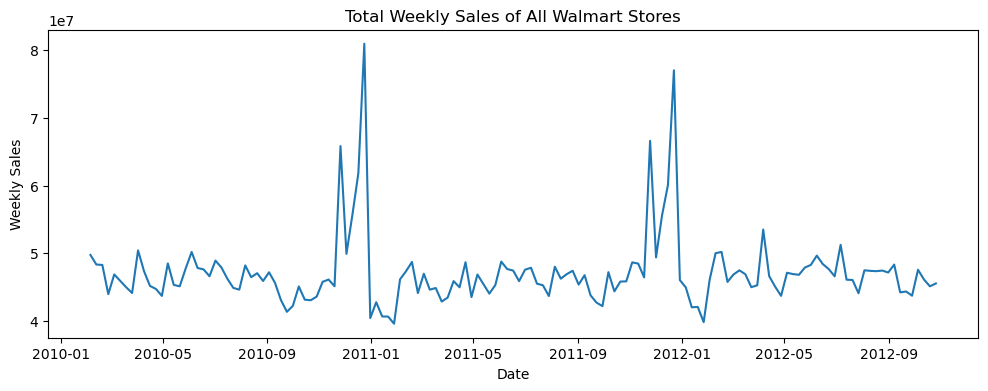

(143,)


In [7]:
import matplotlib.pyplot as plt

weekly = df.groupby("Date")["Weekly_Sales"].sum()

plt.figure(figsize=(12, 4))
plt.plot(weekly.index, weekly.values)
plt.title("Total Weekly Sales of All Walmart Stores")
plt.xlabel("Date")
plt.ylabel("Weekly Sales")
plt.show()

print(weekly.shape)

In [8]:
print("Top 5 sales weeks:")
print(weekly.sort_values(ascending=False).head(5))

Top 5 sales weeks:
Date
2010-12-24    80931415.60
2011-12-23    76998241.31
2011-11-25    66593605.26
2010-11-26    65821003.24
2010-12-17    61820799.85
Name: Weekly_Sales, dtype: float64


In [9]:
test_weeks = 26

train = weekly.iloc[:-test_weeks]
test = weekly.iloc[-test_weeks:]

print("Train:", train.index.min().date(), "to", train.index.max().date(), "->", len(train), "weeks")
print("Test: ", test.index.min().date(), "to", test.index.max().date(), "->", len(test), "weeks")

Train: 2010-02-05 to 2012-04-27 -> 117 weeks
Test:  2012-05-04 to 2012-10-26 -> 26 weeks


In [10]:
import numpy as np

def evaluate(actual, predicted, name):
    mae = np.mean(np.abs(actual - predicted))
    rmse = np.sqrt(np.mean((actual - predicted) ** 2))
    mape = np.mean(np.abs((actual - predicted) / actual)) * 100
    print(f"{name}: MAE = {mae:,.0f} | RMSE = {rmse:,.0f} | MAPE = {mape:.2f}%")
    return {"Model": name, "MAE": mae, "RMSE": rmse, "MAPE": mape}

results = []

naive_pred = pd.Series(train.iloc[-1], index=test.index)
results.append(evaluate(test, naive_pred, "Naive (last value)"))

Naive (last value): MAE = 3,157,980 | RMSE = 3,583,173 | MAPE = 6.62%


In [11]:
seasonal_pred = weekly.shift(52).loc[test.index]
results.append(evaluate(test, seasonal_pred, "Seasonal naive (52 weeks ago)"))

Seasonal naive (52 weeks ago): MAE = 1,181,619 | RMSE = 1,455,381 | MAPE = 2.50%


In [12]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

hw_model = ExponentialSmoothing(train.values, trend=None, seasonal="add", seasonal_periods=52).fit()
hw_pred = pd.Series(hw_model.forecast(len(test)), index=test.index)

results.append(evaluate(test, hw_pred, "Holt-Winters"))

Holt-Winters: MAE = 953,039 | RMSE = 1,168,319 | MAPE = 2.02%


c:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:918: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(


In [13]:
ml = pd.DataFrame({"sales": weekly})
ml["holiday"] = df.groupby("Date")["Holiday_Flag"].max()
ml["week_of_year"] = ml.index.isocalendar().week.astype(int)
ml["month"] = ml.index.month
ml["lag_26"] = ml["sales"].shift(26)
ml["lag_52"] = ml["sales"].shift(52)
ml = ml.dropna()

print(ml.shape)
ml.head()

(91, 6)


,sales,holiday,week_of_year,month,lag_26,lag_52
Date,,,,,,
2011-02-04,46153111.12,0,5,2,48204999.12,49750740.50
2011-02-11,47336192.79,1,6,2,46464418.41,48336677.63
2011-02-18,48716164.12,0,7,2,47060952.92,48276993.78
2011-02-25,44125859.84,0,8,2,45909740.44,43968571.13
2011-03-04,46980603.74,0,9,3,47194257.61,46871470.30


In [14]:
from sklearn.ensemble import RandomForestRegressor

features = ["holiday", "week_of_year", "month", "lag_26", "lag_52"]

train_ml = ml[ml.index < test.index.min()]
test_ml = ml.loc[test.index]

rf = RandomForestRegressor(n_estimators=300, random_state=42)
rf.fit(train_ml[features], train_ml["sales"])

rf_pred = pd.Series(rf.predict(test_ml[features]), index=test.index)
results.append(evaluate(test, rf_pred, "Random Forest (lag features)"))

print("Train rows:", len(train_ml), "| Test rows:", len(test_ml))

Random Forest (lag features): MAE = 959,961 | RMSE = 1,323,605 | MAPE = 2.02%
Train rows: 65 | Test rows: 26


In [15]:
results_df = pd.DataFrame(results).sort_values("MAPE").reset_index(drop=True)
results_df["MAE"] = results_df["MAE"].round(0)
results_df["RMSE"] = results_df["RMSE"].round(0)
results_df["MAPE"] = results_df["MAPE"].round(2)
results_df

,Model,MAE,RMSE,MAPE
0,Holt-Winters,953039.0,1168319.0,2.02
1,Random Forest (lag features),959961.0,1323605.0,2.02
2,Seasonal naive (52 weeks ago),1181619.0,1455381.0,2.50
3,Naive (last value),3157980.0,3583173.0,6.62


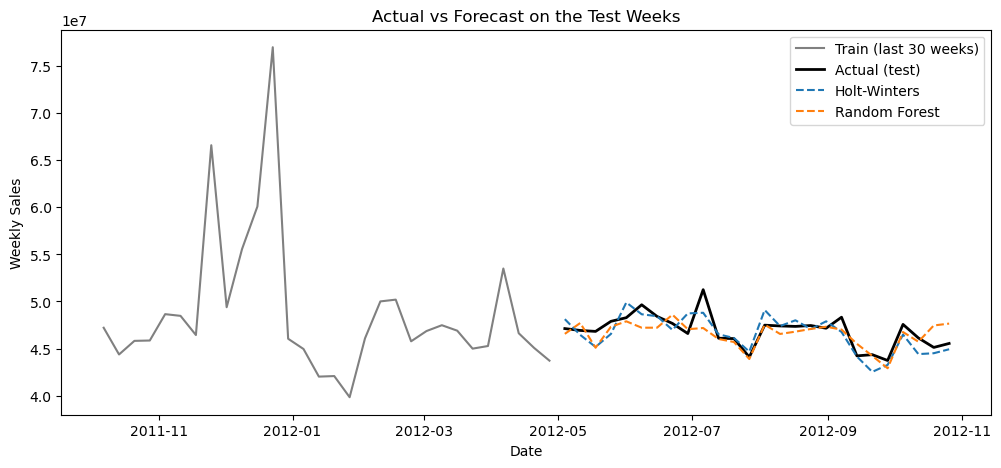

In [16]:
plt.figure(figsize=(12, 5))
plt.plot(train.index[-30:], train.values[-30:], label="Train (last 30 weeks)", color="gray")
plt.plot(test.index, test.values, label="Actual (test)", color="black", linewidth=2)
plt.plot(test.index, hw_pred, label="Holt-Winters", linestyle="--")
plt.plot(test.index, rf_pred, label="Random Forest", linestyle="--")
plt.title("Actual vs Forecast on the Test Weeks")
plt.xlabel("Date")
plt.ylabel("Weekly Sales")
plt.legend()
plt.show()

In [17]:
import os

hw_full = ExponentialSmoothing(weekly.values, trend=None, seasonal="add", seasonal_periods=52).fit()

future_weeks = 26
future_dates = pd.date_range(weekly.index.max() + pd.Timedelta(weeks=1), periods=future_weeks, freq="7D")
future_pred = pd.Series(hw_full.forecast(future_weeks), index=future_dates)

os.makedirs("../outputs", exist_ok=True)
future_pred.rename("Forecast_Sales").to_csv("../outputs/future_forecast.csv", index_label="Date")

print(future_pred.head(3))
print(future_pred.tail(3))

2012-11-02    4.764617e+07
2012-11-09    4.787874e+07
2012-11-16    4.668277e+07
Freq: 7D, dtype: float64
2013-04-12    4.649836e+07
2013-04-19    4.873277e+07
2013-04-26    4.483810e+07
Freq: 7D, dtype: float64


c:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:918: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(


In [18]:
weekly.rename("Weekly_Sales").to_csv("../outputs/weekly_history.csv", index_label="Date")
results_df.to_csv("../outputs/model_comparison.csv", index=False)

print(os.listdir("../outputs"))

['future_forecast.csv', 'model_comparison.csv', 'weekly_history.csv']
